In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import re,time
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import nltk
import os
import helper as h
from torchtext.data.utils import get_tokenizer
import spacy
from collections import Counter
from torchtext.vocab import build_vocab_from_iterator
from torch.utils.data import Dataset,DataLoader
from torch.nn.utils.rnn import pad_sequence

In [26]:
import re
import string
import time
from textblob import TextBlob
import nltk
from nltk.corpus import stopwords
import emoji
from torchtext.data import get_tokenizer

def remove_html_tags(text):
    pattern=re.compile('<.*?>')
    return pattern.sub(' ',text)

def remove_urls(text):
    pattern=re.compile(r'https?://\S+|www\.\S+')
    return pattern.sub(' ',text)
text = "Visit https://google.com or www.youtube.com for more information."

def remove_punctuations(text):
    exlude=string.punctuation
    for ch in exlude:
        text=text.replace(ch," ")
    return text
def remove_punctuation2(text):
    return text.translate(str.maketrans(' ',' ',string.punctuation))

chat_words = {
    "u": "you",
    "ur": "your",
    "urs": "yours",
    "r": "are",
    "b4": "before",
    "2day": "today",
    "2moro": "tomorrow",
    "2nite": "tonight",
    "4": "for",
    "4u": "for you",
    " gr8": "great",
    "gud": "good",
    "gonna": "going to",
    "wanna": "want to",
    "gotta": "got to",
    "kinda": "kind of",
    "lemme": "let me",
    "gimme": "give me",
    "dunno": "don't know",
    "thx": "thanks",
    "thanx": "thanks",
    "ty": "thank you",
    "tysm": "thank you so much",
    "yw": "you're welcome",
    "pls": "please",
    "plz": "please",
    "sry": "sorry",
    "np": "no problem",
    "omg": "oh my god",
    "omw": "on my way",
    "brb": "be right back",
    "btw": "by the way",
    "idk": "I don't know",
    "ik": "I know",
    "ikr": "I know, right",
    "imo": "in my opinion",
    "imho": "in my humble opinion",
    "tbh": "to be honest",
    "ngl": "not gonna lie",
    "asap": "as soon as possible",
    "fyi": "for your information",
    "afaik": "as far as I know",
    "lol": "laughing out loud",
    "lmao": "laughing my ass off",
    "rofl": "rolling on the floor laughing",
    "smh": "shaking my head",
    "ttyl": "talk to you later",
    "cya": "see you",
    "cu": "see you",
    "wyd": "what are you doing",
    "wya": "where are you",
    "hbu": "how about you",
    "hru": "how are you",
    "sup": "what is up",
    "wassup": "what is up",
    "dm": "direct message",
    "irl": "in real life",
    "bff": "best friend forever",
    "bf": "boyfriend",
    "gf": "girlfriend",
    "bro": "brother",
    "sis": "sister",
    "fam": "family",
    "ppl": "people",
    "bc": "because",
    "bcz": "because",
    "cuz": "because",
    "coz": "because",
    "w/": "with",
    "w/o": "without",
    "abt": "about",
    "msg": "message",
    "pic": "picture",
    "pics": "pictures",
    "vid": "video",
    "app": "application",
    "tht": "that",
    "dat": "that",
    "dis": "this",
    "dey": "they",
    "n": "and",
    "nd": "and",
    "bday": "birthday",
    "congrats": "congratulations",
    "prob": "probably",
    "def": "definitely",
    "bcuz": "because",
    "sec": "second",
    "min": "minute",
    "tmr": "tomorrow",
    "nite": "night",
    "gn": "good night",
    "gm": "good morning",
    "tc": "take care",
    "jk": "just kidding",
    "ic": "I see",
    "ofc": "of course",
    "obv": "obviously",
    "legit": "legitimate",
    "tmi": "too much information",
    "fomo": "fear of missing out",
    "yolo": "you only live once",
    "goat": "greatest of all time",
    "afk": "away from keyboard",
    "gg": "good game",
    "wp": "well played",
    "nvm": "never mind",
    "msg me": "message me",
    "xoxo": "hugs and kisses"
}
def repalce_chatwords(text):
    new_text=[]
    for word in text.split():
        if word.lower() in chat_words:
            new_text.append(chat_words[word.lower()])
        else:
            new_text.append(word)
    return " ".join(new_text)
def check_spelling(text):
    textblob=TextBlob(text)
    return textblob.correct().string

def remove_stopwords(text):
    new_text=[]
    for word in text.split():
        if word in stopwords.words('english'):
            new_text.append(' ')
        else:
            new_text.append(word)

    x=new_text[:]
    new_text.clear()
    return ' '.join(x)

def demojize_text(text):
    new_text=emoji.demojize(text)
    return new_text


def tokenize_data(text):
    tokenizer=get_tokenizer('spacy')
    return tokenizer(text)

In [25]:
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 7.1 MB/s  0:00:00


In [5]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


drive  sample_data


In [10]:

# Paste your copied path here (it will look similar to this)
file_path = '/content/drive/MyDrive/IMDB Dataset.csv'

# Load the CSV into a DataFrame
data= pd.read_csv(file_path)

# Display the first few rows
data.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [9]:
os.listdir()

['.config', 'drive', 'helper.py', 'sample_data']

In [ ]:
data=pd.read_csv('Dataset/IMDB Dataset.csv')

In [27]:
data['review']=data['review'].apply(remove_html_tags)

In [28]:
data['review']=data['review'].apply(remove_urls)

In [29]:
data['review']=data['review'].apply(repalce_chatwords)

In [30]:
data.isnull().sum()

,0
review,0
sentiment,0


In [31]:
data['sentiment'].unique()

array(['positive', 'negative'], dtype=object)

In [32]:
data['sentiment']=data['sentiment'].map({'positive':1, 'negative':0})

In [33]:
data.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. The filming tec...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


In [34]:
data.iloc[0]

,0
review,One of the other reviewers has mentioned that ...
sentiment,1


In [35]:
def lower_case(text):
    return text.lower()

In [36]:
data['review']=data['review'].apply(lower_case)

In [37]:
data.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production. the filming tec...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there's a family where a little boy ...,0
4,"petter mattei's ""love in the time of money"" is...",1


In [38]:
nlp = spacy.load("en_core_web_sm")

In [39]:
tokenizer=get_tokenizer('spacy',language='en_core_web_sm')

In [40]:
text = "Hello, welcome to Natural Language Processing!"

tokens = tokenizer(text)

print(tokens)

['Hello', ',', 'welcome', 'to', 'Natural', 'Language', 'Processing', '!']


In [41]:
data['token']=data['review'].apply(tokenizer)

In [42]:
data.head()

,review,sentiment,token
0,one of the other reviewers has mentioned that ...,1,"[one, of, the, other, reviewers, has, mentione..."
1,a wonderful little production. the filming tec...,1,"[a, wonderful, little, production, ., the, fil..."
2,i thought this was a wonderful way to spend ti...,1,"[i, thought, this, was, a, wonderful, way, to,..."
3,basically there's a family where a little boy ...,0,"[basically, there, 's, a, family, where, a, li..."
4,"petter mattei's ""love in the time of money"" is...",1,"[petter, mattei, 's, "", love, in, the, time, o..."


In [43]:
train_data,test_data=train_test_split(data,test_size=0.2,random_state=42)

In [44]:
word_counts = Counter()

for tokens in train_data["token"]:
    if isinstance(tokens, list):
        word_counts.update(tokens)

print(word_counts.most_common(10))

[('the', 533272), ('.', 436724), (',', 433689), ('and', 258390), ('a', 256663), ('of', 231545), ('to', 214975), ('is', 173683), ('it', 151786), ('in', 148764)]


In [45]:
vocab_size=20000
word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}
for word, count in word_counts.most_common(vocab_size - 2):
    word2idx[word] = len(word2idx)
print("Vocabulary size:", len(word2idx))

Vocabulary size: 20000


In [46]:
train_data.head()

,review,sentiment,token
39087,that's what i kept asking myself during the ma...,0,"[that, 's, what, i, kept, asking, myself, duri..."
30893,i did not watch the entire movie. i could not ...,0,"[i, did, not, watch, the, entire, movie, ., i,..."
45278,a touching love story reminiscent of in the m...,1,"[a, touching, love, story, reminiscent, of, i..."
16398,this latter-day fulci schlocker is a totally a...,0,"[this, latter, -, day, fulci, schlocker, is, a..."
13653,"first of all, i firmly believe that norwegian ...",0,"[first, of, all, ,, i, firmly, believe, that, ..."


In [47]:
def numericalize(tokens):
    return [
        word2idx.get(word, word2idx["<UNK>"])
        for word in tokens
    ]

train_data["input_ids"] = train_data["token"].apply(numericalize)
test_data["input_ids"] = test_data["token"].apply(numericalize)

In [48]:
print(train_data[["token", "input_ids"]].head())

                                                   token  \
39087  [that, 's, what, i, kept, asking, myself, duri...   
30893  [i, did, not, watch, the, entire, movie, ., i,...   
45278  [a, touching, love, story, reminiscent, of, i...   
16398  [this, latter, -, day, fulci, schlocker, is, a...   
13653  [first, of, all, ,, i, firmly, believe, that, ...   

                                               input_ids  
39087  [14, 16, 57, 12, 800, 2155, 544, 316, 2, 121, ...  
30893  [12, 81, 30, 116, 2, 453, 21, 3, 12, 88, 30, 1...  
45278  [6, 1336, 126, 74, 2841, 7, 1, 2, 1276, 20, 12...  
16398  [13, 1578, 17, 263, 2696, 1, 9, 6, 458, 4483, ...  
13653  [101, 7, 38, 4, 12, 5491, 270, 14, 8214, 110, ...  


In [49]:
print(type(train_data["token"].iloc[0]))
print(train_data["token"].iloc[0])

<class 'list'>
['that', "'s", 'what', 'i', 'kept', 'asking', 'myself', 'during', 'the', 'many', 'fights', ',', 'screaming', 'matches', ',', 'swearing', 'and', 'general', 'mayhem', 'that', 'permeate', 'the', '84', 'minutes', '.', 'the', 'comparisons', 'also', 'stand', 'up', 'when', 'you', 'think', 'of', 'the', 'one', '-', 'dimensional', 'characters', ',', 'who', 'have', 'so', 'little', 'depth', 'that', 'it', 'is', 'virtually', 'impossible', 'to', 'care', 'what', 'happens', 'to', 'them', '.', 'they', 'are', 'just', 'badly', 'written', 'cyphers', 'for', 'the', 'director', 'to', 'hang', 'his', 'multicultural', 'beliefs', 'on', ',', 'a', 'topic', 'that', 'has', 'been', 'done', 'much', 'better', 'in', 'other', 'dramas', 'both', 'on', 'tv', 'and', 'the', 'cinema', '.', 'i', 'must', 'confess', ',', 'i', "'m", 'not', 'really', 'one', 'for', 'spotting', 'bad', 'performances', 'during', 'a', 'film', ',', 'but', 'it', 'must', 'be', 'said', 'that', 'nichola', 'burley', '(', 'as', 'the', 'heroine', 

In [50]:
class IMDBDataset(Dataset):
    def __init__(self,data):
        self.reviews=data['input_ids'].tolist()
        self.label=data['sentiment'].tolist()

    def __len__(self):
        return len(self.reviews)

    def __getitem__(self,idx):
        return (torch.tensor(self.reviews[idx],dtype=torch.long),
                torch.tensor(self.label[idx],dtype=torch.float)
                )

In [51]:
PAD_IDX = word2idx["<PAD>"]
def collate_fn(batch):
    reviews,labels=zip(*batch)
    lenghts=torch.tensor([len(x) for x in reviews])
    reviews=pad_sequence(reviews,batch_first=True,padding_value=PAD_IDX)
    labels=torch.stack(labels)
    return reviews,lenghts,labels

In [52]:
train_dataset=IMDBDataset(train_data)
test_dataset=IMDBDataset(test_data)
train_loader=DataLoader(train_dataset,
                        batch_size=64,
                        shuffle=True,
                        collate_fn=collate_fn
                       )
test_loader=DataLoader(test_dataset,
                       batch_size=64,
                       shuffle=False,
                       collate_fn=collate_fn
                      )

In [53]:
reviews, lengths, labels = next(iter(train_loader))

print("Reviews:", reviews.shape)
print("Lengths:", lengths.shape)
print("Labels:", labels.shape)

Reviews: torch.Size([64, 1096])
Lengths: torch.Size([64])
Labels: torch.Size([64])


In [74]:
class RNN(nn.Module):
    def __init__(self,vocab_size,embeding_dim,hid_dim):
        super(RNN,self).__init__()
        self.embedding=nn.Embedding(num_embeddings=vocab_size,
                                    embedding_dim=embedding_dim,
                                    )
        self.rnn=nn.RNN(input_size=embedding_dim,
                        hidden_size=hid_dim,
                        batch_first=True)
        self.fc=nn.Linear(in_features=hid_dim,out_features=1)
        self.dropout = nn.Dropout(0.4)
    def forward(self,x,length):
        embedded=self.embedding(x)
        from torch.nn.utils.rnn import pack_padded_sequence
        packed=pack_padded_sequence(embedded,
                                  length.cpu(),
                                  batch_first=True,
                                  enforce_sorted=False)
        out,hidden=self.rnn(packed)
        hidden=hidden[-1]
        hidden=self.dropout(hidden)
        result=self.fc(hidden)
        return result.squeeze(1)


In [75]:
vocab_size=len(word2idx)
embedding_dim=100
hidden_dim=128

device='cuda' if torch.cuda.is_available() else 'cpu'

model=RNN(vocab_size=vocab_size,
          embeding_dim=embedding_dim,
          hid_dim=hidden_dim
         ).to(device)
print(model)

RNN(
  (embedding): Embedding(20000, 100)
  (rnn): RNN(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.4, inplace=False)
)


In [76]:
optimizer=optim.Adam(model.parameters(),lr=0.0001,weight_decay=1e-4)
loss_fn=nn.BCEWithLogitsLoss()

In [82]:

epochs = 10

total_train_loss = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for reviews, length, labels in train_loader:
        reviews = reviews.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        pred = model(reviews, length)
        loss = loss_fn(pred, labels.float())
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)
        optimizer.step()

        total_loss += loss.item()
        prediction = (torch.sigmoid(pred) >= 0.5).float()
        correct += (prediction == labels).sum().item()
        total += labels.numel()

    epoch_loss = total_loss / len(train_loader)
    total_train_loss.append(epoch_loss)
    accuracy = (correct / total) * 100

    print(
        f"Epoch: {epoch+1} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch: 1 | Loss: 0.2397 | Accuracy: 91.00%
Epoch: 2 | Loss: 0.2531 | Accuracy: 90.30%
Epoch: 3 | Loss: 0.2368 | Accuracy: 91.12%
Epoch: 4 | Loss: 0.2327 | Accuracy: 91.32%
Epoch: 5 | Loss: 0.2259 | Accuracy: 91.47%
Epoch: 6 | Loss: 0.2321 | Accuracy: 91.19%
Epoch: 7 | Loss: 0.2135 | Accuracy: 92.00%
Epoch: 8 | Loss: 0.2255 | Accuracy: 91.55%
Epoch: 9 | Loss: 0.2182 | Accuracy: 91.77%
Epoch: 10 | Loss: 0.2093 | Accuracy: 92.36%


In [83]:

model.eval()

total_test_loss = []
correct = 0
total = 0

with torch.no_grad():
    for review, length, label in test_loader:

        review = review.to(device)
        label = label.to(device)

        pred = model(review, length=length)

        loss = loss_fn(pred, label)
        total_test_loss.append(loss.item())

        prediction = (torch.sigmoid(pred) >= 0.5).float()

        correct += (prediction == label).sum().item()
        total += label.numel()

accuracy = (correct / total) * 100
avg_test_loss = sum(total_test_loss) / len(total_test_loss)

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}%")


Test Loss: 0.4079
Test Accuracy: 87.36%


In [84]:
torch.save(model.state_dict(),"Vanilla_RNN.pth")

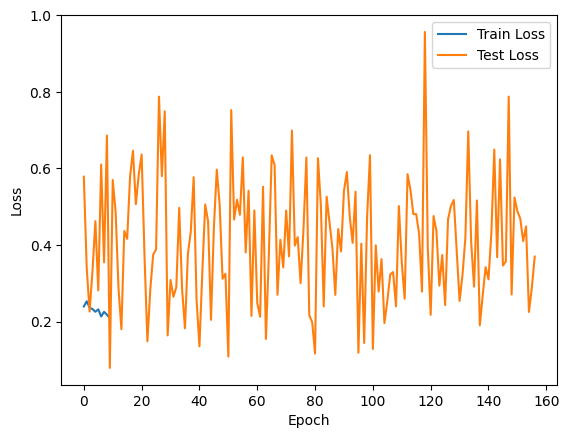

In [85]:

clean_test_loss = [loss.cpu().item() if isinstance(loss, torch.Tensor) else loss for loss in total_test_loss]

plt.plot(total_train_loss, label="Train Loss")
plt.plot(clean_test_loss, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()